# Building an Image Dataset by Scraping: Traditional African Drums

**P2 Notebook 1 — Team DataStars**

This notebook builds our own labeled dataset of eight traditional African drums: we pick the classes, search the web for them, download whatever comes back, and keep an exact record of it. We started from the provided scraper notebook, replaced its guitar example with our classes, scaled the run up to a full-size dataset, and added our reasoning for the classes, the queries and every argument we pass the scraper. The download-integrity check, the accounting table and the manifest come from the provided notebook; we extended them where our run needed it.

## Learning objectives

- Choose image classes that make a learnable, non-trivial classification problem
- Write several search queries per class and explain why one query is not enough
- Run a scraper with arguments you can justify, rather than defaults you inherited
- Account for the gap between images requested, images downloaded, and images readable
- Export a manifest that records what you actually trained on

## Background

You need to be comfortable with paths and folders (`pathlib`), with opening images in PIL, and
with building a DataFrame from a list of dictionaries. The scraping mechanics themselves are
handled for you by `ddgs_scraper.py`, which sits next to this notebook — you are expected to read
that module before you run it, because this assignment asks you to justify the arguments you pass.

Scraped images are copyrighted by whoever made them. They are fine to use for coursework, but do
**not** redistribute them, do **not** commit any of them to your repo, and do **not** publish your
dataset. They live in your local class data folder, outside the repo.

## This notebook covers

1. What the scraper does
2. Declaring your classes and queries
3. Running the scraper
4. Accounting for what came back
5. A first look at the images
6. Turning the records into a manifest

**Prerequisites:** none — this is the first notebook of P2.

**Dataset:** yours. Built here from Bing image search, via the `ddgs` package.

**References:** <https://pypi.org/project/ddgs/>

In [3]:
import json
import random
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',100)

plt.style.use('dark_background')

import warnings
warnings.filterwarnings('ignore')

# The scraper lives in ddgs_scraper.py, in this same folder. Keep the two files
# together — if you move this notebook into your repo, move the module with it.
import ddgs_scraper

## 1. What the scraper does

`ddgs_scraper.py` wraps the `ddgs` package, which queries web image search. By default it asks Bing
Images directly — the same index DuckDuckGo Images draws its results from — because that is the
backend that works reliably (see `backend` in section 3). The pieces you will actually call are:

| Function | What it does |
|---|---|
| `search_images(query, ...)` | One search, paged until it has enough results. Returns raw result records — image URL, page URL, title, reported size |
| `download_image(url, ...)` | Fetches one URL and returns an RGB PIL image, or `None` if it isn't one |
| `passes_image_filters(img, ...)` | Checks a downloaded image against size and aspect-ratio limits |
| `scrape_class(label, queries, ...)` | All queries for one class, into one folder |
| `build_image_dataset(class_queries, ...)` | Every class. **This is the one you call.** |

Two things the scraper deliberately does *not* do, because they are your job in Notebook 2:
it does not check for duplicate images, and it does not judge whether the picture is actually of
the thing you searched for.

Read the module before running it. The arguments below are not magic numbers and you will be asked
to defend them.

In [4]:
# The scraper's own documentation for the function we call. Read it before running section 3.
help(ddgs_scraper.build_image_dataset)

Help on function build_image_dataset in module ddgs_scraper:

build_image_dataset(class_queries: dict, save_dir: str | pathlib.Path, images_per_class: int = 250, results_per_query: int = 200, aspect_ratio_range: tuple = (0.5, 2.0), min_resolution: tuple = (200, 200), per_image_timeout: int = 10, backend: str = 'bing', safesearch: str = 'moderate', region: str = 'us-en', require_query_match: bool = True, query_delay: tuple = (2.0, 5.0), continue_on_error: bool = True, verbose: bool = True) -> tuple[list[dict], dict]
    Download a labeled image dataset from an image search engine.

    One folder per class is created inside save_dir. Every class may have
    several search queries, and results from all of a class's queries land in
    the same folder — using several queries per class is how you get a class
    that looks like the whole category instead of one narrow slice of it.
    Every query is used: downloads take turns between a class's queries, so
    each supplies a roughly equal

## 2. Declaring your classes and queries

### 2.1 Choosing classes

Your categories are your choice, within the constraints in the assignment prompt: 3–10 classes, at
least 200 usable images each *after* cleaning, not a standard benchmark, and visually
distinguishable but not trivially so.

The last one is the constraint people get wrong. Classes a model separates at 99% teach you
nothing, and classes that are genuinely ambiguous teach you nothing either. Aim for categories a
person could sort reliably but not instantly — different hand tools, dog breeds, architectural
styles, cloud types, guitar body shapes.

### 2.2 Why several queries per class

A single search returns a narrow, repetitive slice of a category. Search "hammer" and you get a
thousand near-identical product photos of claw hammers on white backgrounds. Your model will learn
"white background" and fall over on the first photo taken in a garage.

Several queries per class widen what the class looks like, and they are also the main reason a
class survives deduplication with enough images left. The scraper uses every query: it searches
them all, then takes turns between them when downloading — first result of each query, then the
second of each — so each query supplies a roughly equal share of the class. If one query runs dry,
the others make up the difference. The run log reports how many images came from each query;
the `query` column of the manifest records it per image.

### 2.3 Our classes: traditional African drums

We are building an **8-class dataset of traditional African drums**. Drums suit this assignment because each type is a physical object with a fixed construction that someone who knows them can name from a photograph: the body shape, the number of heads, how the head is tensioned, and how the drum is played all differ from type to type. Descriptions below are the *typical* form of each drum; real instruments, especially ones sold in drum shops, vary.

| Class | Typical form | Region |
|---|---|---|
| `djembe` | Goblet-shaped, single-headed, rope-tuned hand drum | West Africa (Mande) |
| `talking_drum` | Hourglass body, two heads joined by tension cords, pitch changed by squeezing, played with a curved stick | West Africa (Yoruba *dùndún*, Akan, Dagomba) |
| `dunun` | Cylindrical, double-headed bass drum played with a stick, often with a bell on top | West Africa (Manding) |
| `bata` | Double-headed drum whose two heads are different sizes, played on the lap | Yoruba (Nigeria) |
| `sabar` | Tall, tapered, single-headed, tuned with pegs and rope, played with one hand and one stick | Senegal and Gambia (Wolof) |
| `bougarabou` | Single-headed, tall open-bottomed drum, often played as a set of several | Casamance (southern Senegal) |
| `bendir` | Wide, shallow circular frame drum held in the hand, with snare strings under the head | North Africa (Morocco, Algeria) |
| `ashiko` | Single-headed, straight-sided conical drum, wider at the head | Yoruba (Nigeria) |

Labels are lowercase ASCII with underscores because they become folder names and filename prefixes (`bata` stands for batá).

**Checking our classes against the four constraints in the prompt**

1. **3–10 classes.** We have 8. That is enough for a confusion matrix with real structure, and few enough to scrape and clean by hand.
2. **At least 200 usable images per class after cleaning.** We plan to save 350 per class so that cleaning wrong subjects and duplicates still leaves 200. The least-photographed drums, **`bougarabou` and `ashiko`**, are our biggest risk, and the accounting table in section 4.2 is where we check them first. If a class cannot reach 200 genuine images we replace it with a different drum rather than padding it with junk.
3. **Not a standard benchmark.** No curated drum-type dataset exists that we know of. ImageNet, which the pretrained Keras applications learned from, has only a generic *drum* category, so the pretrained features know what a drum looks like but were never trained to tell a djembe from an ashiko.
4. **Visually distinguishable but not trivial.** A person can separate these drums from silhouette alone in the easy cases: goblet (`djembe`), hourglass (`talking_drum`), cylinder (`dunun`), flat circle (`bendir`). The hard cases are neighbours that share a construction: single-headed, rope-tuned, tapered West African hand drums.

**Where we expect the model to struggle**

- **`djembe` vs `ashiko`.** Both are single-headed, rope-tuned hand drums with a similar head. The difference is mostly the lower body (goblet with a narrow stem vs a straight cone), which is hidden when the drum is photographed from above or while it is being played.
- **`sabar` vs `bougarabou`.** Both are tall single-headed Senegalese drums, often photographed in sets or in performance.
- **`dunun` vs `bata`.** Both are double-headed drums often photographed lying on their side or on a lap, and both usually appear in sets of three.
- **Photos with several instruments.** Drum circles, ensembles and sets will put other classes' drums into a class's images; we handle these by hand in Notebook 2.
- **Dataset-level bias we want to measure, not just hope away.** Search wording changes the kind of photo we get (product shot on a white background vs a performance), decoration and carving style are cultural rather than structural, and retail sites add watermarks and logos. If these line up with a class the model can use them as a shortcut, so we check the per-class mean images in Notebook 2 and the saliency maps in Notebook 4.

### 2.4 Our prediction, recorded before any modeling

**The pair we expect the model to confuse most is `djembe` and `ashiko`.** Our next two are `sabar` / `bougarabou` and `dunun` / `bata`. Notebook 3 checks this prediction against the real confusion matrix.

### 2.5 Our queries

Three queries per class, written so each one reaches a different slice of the class: a general name, a regional or cultural variant, and a wording aimed at the whole drum rather than a detail. Known risks in the wording:

- The word **`dundun`** is the Yoruba name for the *talking drum* but is also used for the Manding bass drum. The second `dunun` query and the second `talking_drum` query both contain it, so each may return the other's instrument. We look for this in Notebook 2's cross-class duplicate pass.
- **`bata`** is also a well-known shoe brand. Every `bata` query also says *drum*, which should keep shoe results out, but we check the images in section 5.
- Queries ending in *isolated* or *full view* lean towards product photos on plain backgrounds, which are not what every class's other queries return. This is one of the background biases listed above.

In [5]:
CLASS_QUERIES = {
    'djembe': [
        'traditional African djembe drum',
        'West African djembe wooden drum',
        'djembe goblet drum full view',
    ],
    'talking_drum': [
        'African talking drum hourglass',
        'Yoruba dundun talking drum',
        'West African talking drum tension cords',
    ],
    'dunun': [
        'traditional African dunun bass drum',
        'West African dundun cylindrical drum',
        'Guinean dunun drum',
    ],
    'bata': [
        'traditional Yoruba bata drum',
        'Nigerian bata double headed drum',
        'African bata drum isolated',
    ],
    'sabar': [
        'traditional Senegalese sabar drum',
        'Wolof sabar wooden drum',
        'Senegal sabar drum full view',
    ],
    'bougarabou': [
        'traditional bougarabou African drum',
        'Senegal bougarabou wooden drum',
        'Casamance bougarabou hand drum',
    ],
    'bendir': [
        'North African bendir frame drum',
        'Moroccan bendir traditional drum',
        'Algerian bendir circular drum',
    ],
    'ashiko': [
        'traditional African ashiko drum',
        'wooden conical ashiko hand drum',
        'African ashiko drum full view',
    ],
}

# Fail here, before any scraping, if a label or query is unusable as a folder name or search term
CLASS_QUERIES = ddgs_scraper.validate_class_queries(CLASS_QUERIES)
assert 3 <= len(CLASS_QUERIES) <= 10, 'the assignment requires 3-10 classes'

for label, queries in CLASS_QUERIES.items():
    print(f'{label:<14} {len(queries)} queries')

djembe         3 queries
talking_drum   3 queries
dunun          3 queries
bata           3 queries
sabar          3 queries
bougarabou     3 queries
bendir         3 queries
ashiko         3 queries


## 3. Running the scraper

The settings we use are sized for the full dataset, not a demonstration (section 3.3 gives the numbers and the reasons).

To end up with 200 usable images per class after Notebook 2's cleaning, plan to save 300–400 per class here. You will lose images to wrong subjects, duplicates, and files that turn out not to open.

Each argument is a decision you have to justify in your writeup:

- `save_dir` — where the images go: your local class data folder, **never** inside your repo. Only the manifest is committed
- `images_per_class` — how many you keep. Set it above your target, not at it
- `results_per_query` — how many search results to collect, fetched a page at a time. Most will not survive download and filtering
- `min_resolution` — a floor on quality. Small images look terrible resized up to 224×224
- `aspect_ratio_range` — rejects banners and infographics, which are rarely pictures of your subject
- `per_image_timeout` — seconds allowed for one download, start to finish. Each image gets one attempt; a slow or dead host is skipped, not retried
- `backend` — which search engine `ddgs` asks. `'bing'` is the reliable one. DuckDuckGo's image results come from Bing anyway, and the `'duckduckgo'` backend currently fails on every request
- `safesearch` — leave it at `'moderate'`. Note that the `'bing'` backend ignores it and always applies Bing's default, which is Moderate
- `region` — changes what you get back. Say so if you change it. Also ignored by `'bing'`
- `require_query_match` — drops results that never mention your query (section 3.2). Leave it on unless your query's words genuinely do not appear in image titles

### 3.1 Expect to be rate limited

Search engines throttle scrapers, and when they do the `ddgs` package reports **"No results
found"** rather than an explicit rate-limit error. That looks identical to a query that genuinely
matched nothing.

The scraper retries a few times with backoff before believing it, and marks any class that ends
with zero images as `empty` in the summary rather than `ok`. You still need to watch for it:

- A class reported as `empty`, or with far fewer images than its neighbours, is almost always
  throttling — not a bad query
- The fix is to wait several minutes and re-run **just that class**. Filenames restart at `_0000` on every
  scrape, so a re-run must start from an empty folder (the cell below clears a class's folder before it re-scrapes it)
- Scraping five classes at full scale in one uninterrupted run is unlikely to work. Plan to do it
  in batches over more than one sitting
- This is the single most common reason a class comes up short of 200. Start early

### 3.2 Watch for results from someone else's search

Occasionally the search engine answers with a page of results for a different query entirely — a
search for "acoustic guitar" once came back as 35 stills from a 1991 movie. Those images download
fine and pass every size filter, so nothing downstream would stop them landing in your class folder.

The scraper checks every page it gets back. A result whose title, page URL, and image URL never
mention a word of your query is dropped, and a page where fewer than half the results mention it is
treated as a bad response and retried, the same way an empty page is.

This is a guard against garbage, **not** a label check: an electric guitar titled "guitar" still
passes a query for "acoustic guitar". Catching those is what section 5 and Notebook 2 are for.

### 3.3 Our settings and why

| Argument | Our value | Why |
|---|---|---|
| `save_dir` | `~/MSDS565_data/P2_images` | Outside the repo: the images are copyrighted and must never be committed, and a repo with thousands of images would also hit GitHub's size limits. Only the manifest goes in the repo. |
| `images_per_class` | 350 | The target is 200 usable images after cleaning. Cleaning removes wrong subjects (drawings, other instruments, people with no drum visible) and duplicates, so we keep 150 images of headroom per class. |
| `results_per_query` | 250 | Three queries of 250 gives about 750 candidates per class for 350 saved images. Many candidates fail to download or fail the filters, so we need well over twice the number we keep. |
| `min_resolution` | (200, 200) | The models take 224×224 input, so a 200 pixel side is scaled up by only about 12%. A stricter floor such as 224 would discard images of the rarer drums, which is the shortage we are most worried about. |
| `aspect_ratio_range` | (0.5, 2.0) | Upright drums photographed in portrait (`djembe`, `sabar`, `dunun`) are roughly 2:3 to 3:4, and drums lying on their side are landscape; both sit inside this range. Banners, infographics and tall collages, which are rarely a single drum, fall outside it. |
| `per_image_timeout` | 10 s | One attempt per image, as in the scraper. A host that has not delivered in 10 seconds is skipped; there are plenty of other candidates. |
| `backend` | `'bing'` | The scraper's documented reliable choice. DuckDuckGo's image results come from Bing anyway, and the `'duckduckgo'` backend currently fails. |
| `safesearch` | `'moderate'` | The subject is musical instruments, so there is no reason to loosen or tighten it. The `bing` backend ignores it and always applies Bing's Moderate. |
| `region` | `'us-en'` | All queries are in English. Also ignored by `bing`. |
| `require_query_match` | `True` | Guards against the search engine answering with a page of results for a different query (3.2). Our queries share common words (*drum*, *African*), so this check is weak here: it will not stop a mislabeled drum, and manual cleaning in Notebook 2 has to do that job. |
| `query_delay` | (2.0, 5.0) s | The scraper's default pause between queries. We raise it if we get throttled. |
| `COOLDOWN` | 30 s | Our own pause between classes, to make rate limiting less likely when several classes run in one cell. |

### 3.4 How we run it

Scraping eight classes in one uninterrupted run is unlikely to work, so the next cell is built to be re-run:

- Each class's records are written to a small file as soon as the class finishes, in a folder next to the image folder (outside the repo), so nothing is lost if the kernel restarts.
- A class is **complete** once it has at least `MIN_READABLE` images saved for the *current* queries. Complete classes are skipped, so re-running the cell after a wait only retries the classes that came up short or empty. Editing a class's queries also makes it count as incomplete.
- `RESCRAPE` forces a class to be scraped again from scratch. **This deletes that class's image folder**, so do not use it, or re-run this notebook at all, once Notebook 2's hand cleaning has started.

In [6]:
from pathlib import Path

# Scraped images NEVER go in your repo — only the manifest does. Point this at
# your local class data folder. The default is a folder in your home directory,
# outside any repo.
IMAGE_DIR = Path.home() / 'MSDS565_data' / 'P2_images'

# One small file per class, so a scrape survives a kernel restart and can resume
RECORDS_DIR = IMAGE_DIR.parent / 'P2_records'
RECORDS_DIR.mkdir(parents=True, exist_ok=True)

IMAGES_PER_CLASS = 350      # saved per class: 200 to survive Notebook 2's cleaning, plus headroom
RESULTS_PER_QUERY = 250     # search results collected per query
MIN_READABLE = 300          # a class needs about this many readable images now to keep 200 after cleaning
COOLDOWN = 30               # seconds to pause between classes
RESCRAPE = []               # classes to scrape again from scratch, e.g. ['bougarabou']. Deletes their image folder.


def load_class_records(label):
    file = RECORDS_DIR / f'{label}.json'
    return json.loads(file.read_text()) if file.exists() else None


def class_is_complete(label):
    saved = load_class_records(label)
    return (saved is not None
            and saved['queries'] == CLASS_QUERIES[label]
            and len(saved['records']) >= MIN_READABLE)


scraped_any = False
for label, queries in CLASS_QUERIES.items():
    if label not in RESCRAPE and class_is_complete(label):
        n = len(load_class_records(label)['records'])
        print(f'[skip] {label}: complete, {n} images saved on an earlier run')
        continue

    if scraped_any:
        time.sleep(COOLDOWN)
    scraped_any = True

    # Filenames restart at _0000 on every scrape, so start the class from an empty folder
    shutil.rmtree(IMAGE_DIR / label, ignore_errors=True)

    class_records, _ = ddgs_scraper.build_image_dataset(
        class_queries={label: queries},
        save_dir=IMAGE_DIR,
        images_per_class=IMAGES_PER_CLASS,
        results_per_query=RESULTS_PER_QUERY,
        aspect_ratio_range=(0.5, 2.0),
        min_resolution=(200, 200),
        per_image_timeout=10,
        backend='bing',
        safesearch='moderate',
        region='us-en',
        require_query_match=True,
        query_delay=(2.0, 5.0),
        verbose=False,
    )
    (RECORDS_DIR / f'{label}.json').write_text(json.dumps({'queries': queries, 'records': class_records}))
    print(f'[done] {label}: {len(class_records)} images saved')

# Everything saved so far, across all sittings, in the same shape build_image_dataset returns
records, classes = [], {}
for label, queries in CLASS_QUERIES.items():
    saved = load_class_records(label)
    class_records = saved['records'] if saved else []
    records.extend(class_records)
    classes[label] = {'saved': len(class_records), 'queries': len(queries),
                      'status': 'ok' if class_records else 'empty'}
summary = {'save_dir': str(IMAGE_DIR.resolve()), 'classes': classes, 'total_saved': len(records)}

short = [label for label, info in classes.items() if info['saved'] < MIN_READABLE]
print(f"\n{summary['total_saved']} images saved to {summary['save_dir']}")
if short:
    print(f'Still below {MIN_READABLE}: {short}. Wait a few minutes and run this cell again.')

[done] djembe: 350 images saved
[done] talking_drum: 350 images saved
[done] dunun: 350 images saved
[done] bata: 350 images saved
[done] sabar: 350 images saved
[done] bougarabou: 350 images saved
[done] bendir: 350 images saved
[done] ashiko: 332 images saved

2782 images saved to /Users/mikeflanders/MSDS565_data/P2_images


## 4. Accounting for what came back

The assignment tracks each class from **requested** through **downloaded** to **readable**. This
section does that for you: 4.1 checks that every saved file actually opens, and 4.2 builds the
table and flags any class at risk of ending up short. Your job is to read the result — a count you
cannot explain is the problem the prompt is warning about, not the fact that images were lost.

### 4.1 Download integrity

Some downloads arrive truncated, empty, or as a different format wearing the wrong extension. The
scraper only saves images it managed to decode, so everything on disk *should* open — this pass
checks instead of assuming. It opens every saved file with PIL inside a `try`/`except`, the same
pattern `U2-2_CNN-8_Explainability` §1 uses, then logs and deletes any file that fails.

This pass checks every file listed in the scrape records, so running it again gives the same answer (a file deleted earlier is reported as unreadable again). It is only meaningful *before* Notebook 2's hand cleaning, which also removes files.

`load()` is what does the checking. `Image.open` only reads the file's header; a truncated file
fails only when its pixels are actually decoded.

In [7]:
from PIL import Image

# Open and fully decode every saved image. Anything PIL cannot read is logged and
# deleted, so Notebook 2 never trips over it.
unreadable = []          # one (label, filename, error) entry per file that failed

for rec in records:
    path = IMAGE_DIR / rec['label'] / rec['filename']
    try:
        with Image.open(path) as img:
            img.load()       # full decode — this is what catches a truncated file
    except Exception as e:
        unreadable.append((rec['label'], rec['filename'], f'{type(e).__name__}: {e}'))
        path.unlink(missing_ok=True)     # delete the unreadable file

print(f'{len(unreadable)} unreadable files found and deleted')
for label, name, error in unreadable[:10]:
    print(f'  {label}/{name} -> {error}')
if len(unreadable) > 10:
    print(f'  ... and {len(unreadable) - 10} more')

0 unreadable files found and deleted


### 4.2 Raw accounting

One row per class: **requested** is the `IMAGES_PER_CLASS` you asked the scraper for,
**downloaded** is what it saved, **unreadable** is what 4.1 deleted, and **readable** is what is
left.

A class is flagged **at risk** when it has fewer than 300 readable images. Notebook 2's cleaning
removes wrong subjects and duplicates, and a class that starts below about 300 rarely keeps the 200
the assignment requires. Re-scrape any flagged class **now**, not after Notebook 2.

In [8]:
rows = []
for label, info in summary['classes'].items():
    n_unreadable = sum(1 for lbl, name, error in unreadable if lbl == label)
    n_readable = info['saved'] - n_unreadable
    rows.append({
        'class': label,
        'queries': info['queries'],
        'requested': IMAGES_PER_CLASS,
        'downloaded': info['saved'],
        'unreadable': n_unreadable,
        'readable': n_readable,
        'status': info['status'],
        'at_risk': n_readable < MIN_READABLE,
    })

counts = pd.DataFrame(rows)

at_risk = counts.loc[counts['at_risk'], 'class'].tolist()
print(f"Output folder: {summary['save_dir']}")
if at_risk:
    print(f'{len(at_risk)} of {len(counts)} classes below {MIN_READABLE} readable images: {at_risk}')
else:
    print(f'All {len(counts)} classes have at least {MIN_READABLE} readable images')
counts

Output folder: /Users/mikeflanders/MSDS565_data/P2_images
All 8 classes have at least 300 readable images


,class,queries,requested,downloaded,unreadable,readable,status,at_risk
0,djembe,3,350,350,0,350,ok,False
1,talking_drum,3,350,350,0,350,ok,False
2,dunun,3,350,350,0,350,ok,False
3,bata,3,350,350,0,350,ok,False
4,sabar,3,350,350,0,350,ok,False
5,bougarabou,3,350,350,0,350,ok,False
6,bendir,3,350,350,0,350,ok,False
7,ashiko,3,350,332,0,332,ok,False


### 4.3 What each query contributed

The scraper takes turns between a class's queries, so each should supply a roughly equal share. A query that supplied far fewer images than its siblings was throttled, ran dry, or returned mostly images that failed the filters, and the class then rests on fewer slices of what the drum looks like.

In [9]:
per_query = (pd.DataFrame(records)
             .groupby(['label', 'query'], sort=False)
             .size()
             .rename('saved')
             .reset_index())
per_query

,label,query,saved
0,djembe,traditional African djembe drum,162
1,djembe,West African djembe wooden drum,32
2,djembe,djembe goblet drum full view,156
3,talking_drum,African talking drum hourglass,109
4,talking_drum,Yoruba dundun talking drum,131
5,talking_drum,West African talking drum tension cords,110
6,dunun,traditional African dunun bass drum,144
7,dunun,West African dundun cylindrical drum,160
8,dunun,Guinean dunun drum,46
9,bata,traditional Yoruba bata drum,122


### 4.4 What the accounting shows

No class flagged at risk. Three queries supplied far frewer images than the others (ashiko - 37, dunun - 46, djembe - 32) but this may suggest that the phrasings were too narrow. the class still got its images from the other two queries so we ill watch what happens with the counts in notebook 2. 

## 5. A first look at the images

Before anything else, look at what you actually downloaded. This is the fastest way to discover
that a query returned drawings, product collages, or pictures of the *word* rather than the thing.

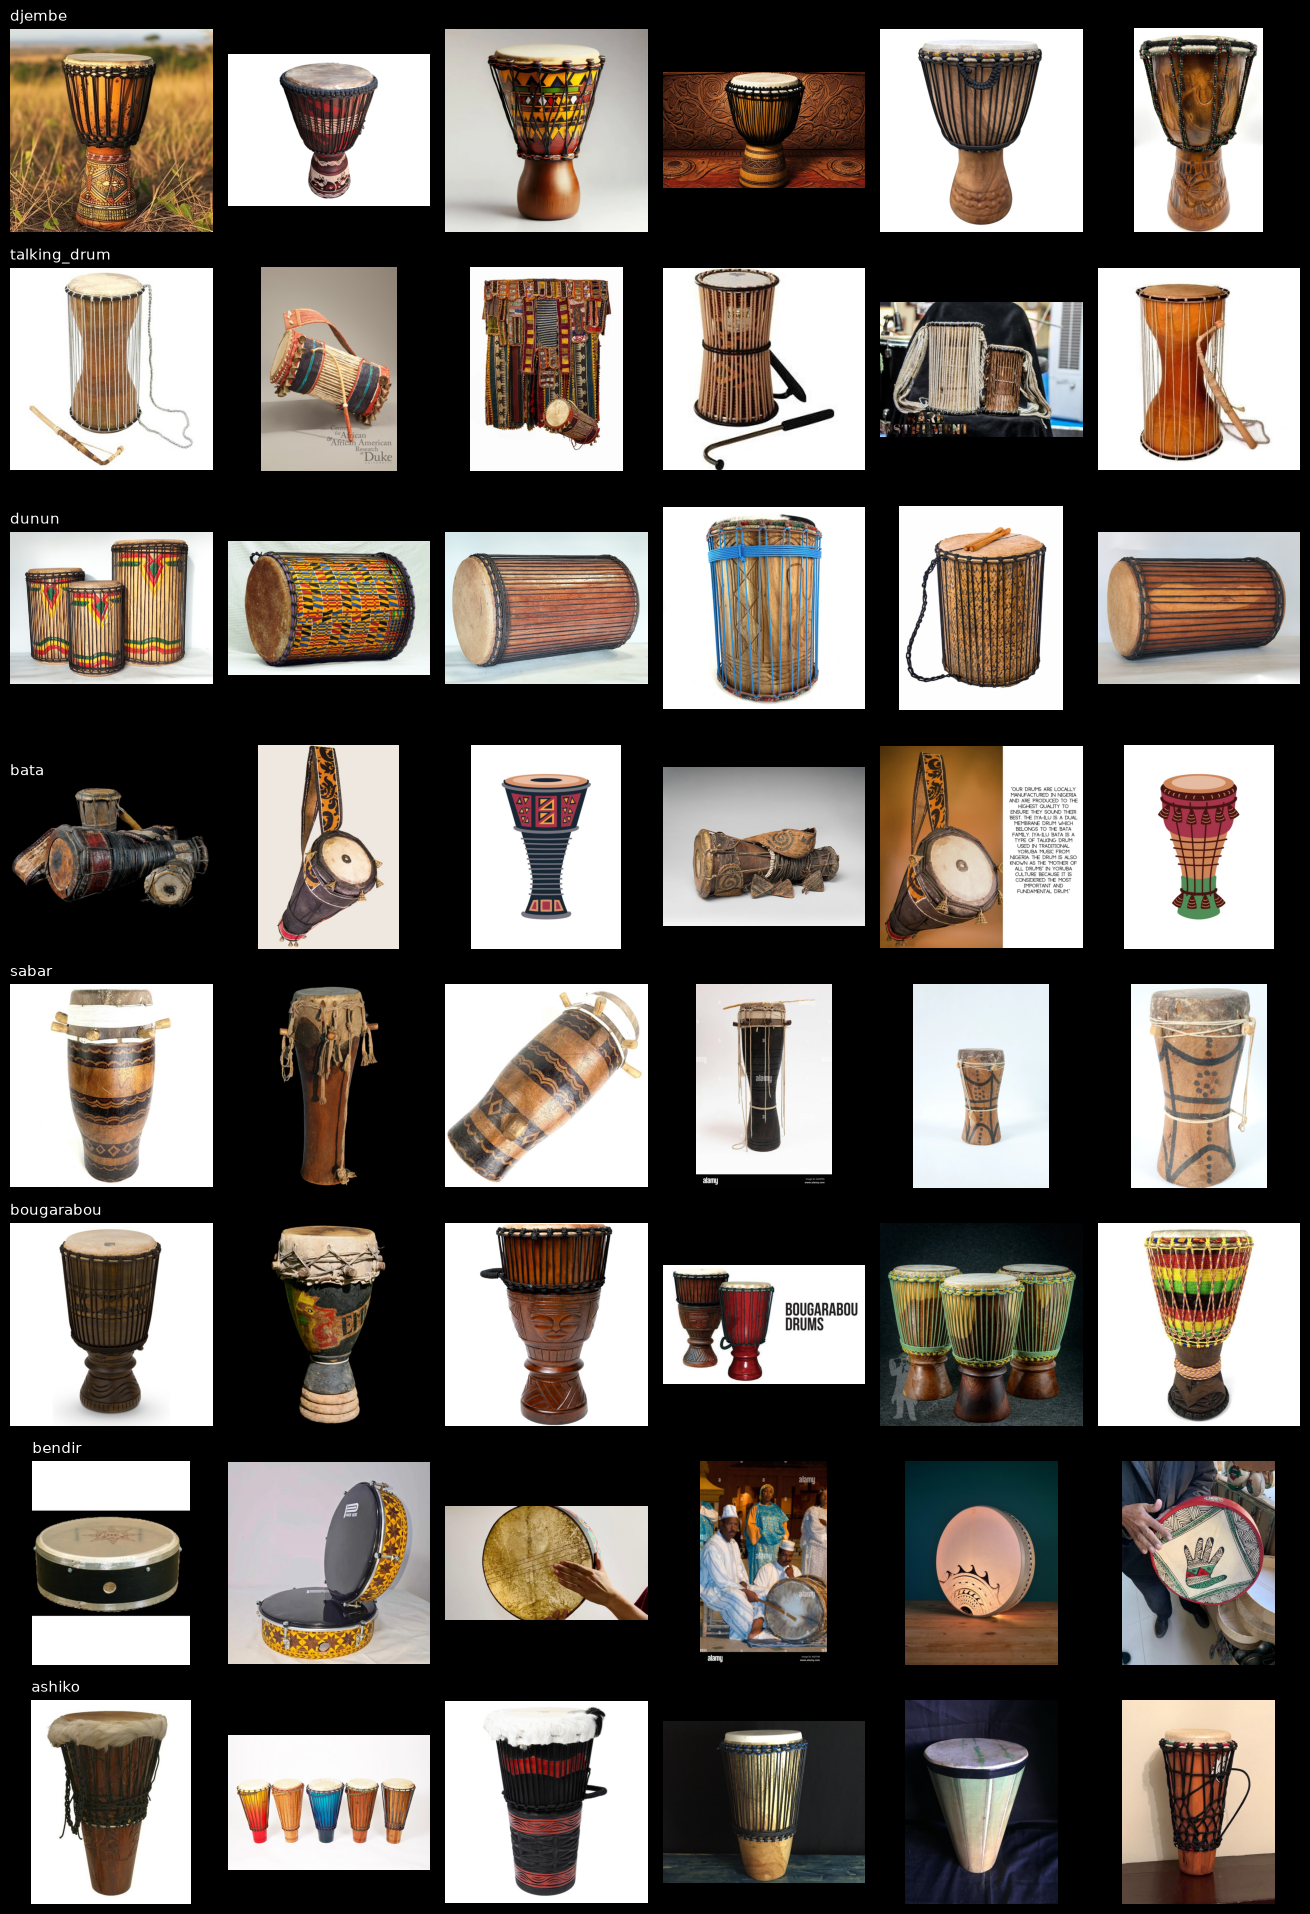

In [10]:
n_show = 6
labels = list(summary['classes'].keys())

fig, axes = plt.subplots(len(labels), n_show, figsize=(2.2 * n_show, 2.4 * len(labels)))
axes = np.atleast_2d(axes)

for r, label in enumerate(labels):
    files = sorted(Path(summary['save_dir'], label).glob('*.jpg'))[:n_show]
    for c in range(n_show):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(files):
            ax.imshow(Image.open(files[c]))
            if c == 0:
                ax.set_title(label, loc='left', fontsize=11)

plt.tight_layout()
plt.show()

### 5.1 What we noticed in the first look

The "traditional x drum" and "full view" queries mostly produce product-style shots. The culuture queries (Yoruba, Wolof, Senegal) produced shots with people, performances, posters, ie. Dunun and Bendir look like product shots on white or wood backgrounds. Sabar and talking drum are more performance-style. There are a number of repeats also. 

## 6. Turning the records into a manifest

`records` is one row per saved image. The manifest is the permanent record of what you trained on,
and it matters more here than in a normal project: **search results change over time, so re-running
this scraper later will not give you the same dataset.** The manifest is the only reproducible
account of the run.

The prompt requires at minimum `filename`, `label`, `source_url`, `query`, and a boolean
`readable`. The scraper supplies everything but `readable`, which comes from the integrity pass in
section 4.1.

Notebook 2 extends this file with a `kept` column. Add to it there; do not overwrite it.

In [11]:
manifest = pd.DataFrame(records)

# readable comes from the integrity pass in 4.1: False for every file it deleted
unreadable_files = {(label, name) for label, name, error in unreadable}
manifest['readable'] = [(label, name) not in unreadable_files
                        for label, name in zip(manifest['label'], manifest['filename'])]

# The columns the prompt requires come first; the rest of the scraper's record follows
required = ['filename', 'label', 'source_url', 'query', 'readable']
manifest = manifest[required + [c for c in manifest.columns if c not in required]]

# This notebook lives in notebooks/, so the repo's data/ folder is one level up
DATA_DIR = Path('..') / 'data'
DATA_DIR.mkdir(exist_ok=True)
manifest.to_csv(DATA_DIR / 'P2_manifest.csv', index=False)

print(f"{len(manifest)} rows written to {DATA_DIR / 'P2_manifest.csv'}")
manifest.groupby('label', sort=False)['readable'].agg(rows='size', readable='sum')

2782 rows written to ../data/P2_manifest.csv


,rows,readable
label,,
djembe,350,350
talking_drum,350,350
dunun,350,350
bata,350,350
sabar,350,350
bougarabou,350,350
bendir,350,350
ashiko,332,332


## Review

This notebook built a labeled dataset of eight traditional African drums from scratch:

1. **The scraper** (`ddgs_scraper.py`) searches for images, downloads results, filters by size and aspect ratio, and saves one folder per class
2. **Classes and queries** are eight drum types with three queries each, chosen and defended against the assignment's four constraints, with a prediction of the most-confused pair recorded before any modeling
3. **Running it** was done in re-runnable batches because of rate limiting, with every scraper argument justified in 3.3
4. **Integrity and accounting** opened every saved file, tracked each class requested → downloaded → readable, and flagged any class at risk of ending up short
5. **Looking at the images** caught problems the filters cannot: the wrong subject, several drums in one picture, and class-specific photo styles
6. **The manifest** (`data/P2_manifest.csv`) is the reproducible record of a scrape that cannot be reproduced by re-running

**Next:** `P2_Images-2_Preprocessing.ipynb` cleans these folders by hand, explores the images, preprocesses them, and splits them for modeling.